# Modelagem e interpretação: Pulsares (HTRU2) + Meteoritos (NASA)

Neste notebook se concentram principalmente os **passos 5 (mineração)** e a base do **passo 6 (avaliação e interpretação)**.


In [1]:
%pip install -q ucimlrepo

import re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (StandardScaler, PowerTransformer, OneHotEncoder,
                                   PolynomialFeatures)
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                           QuadraticDiscriminantAnalysis)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              AdaBoostClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, r2_score, mean_squared_error,
                             recall_score, precision_score)

from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

SCORING = {"AUC_ROC": "roc_auc", "AUC_PR": "average_precision",
           "recall": "recall", "precisão": "precision", "F1": "f1",
           "acc_balanceada": "balanced_accuracy", "acurácia": "accuracy"}

Note: you may need to restart the kernel to use updated packages.


In [2]:
# funções usadas nas duas partes
def run_cv(models, X, y, cv=CV, scoring=SCORING):
    # roda validação cruzada em um dicionário {nome: modelo} e devolve média e desvio
    rows = []
    for name, model in models.items():
        r = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        row = {"modelo": name}
        for k in scoring:
            row[k] = r[f"test_{k}"].mean()
            row[f"{k}_dp"] = r[f"test_{k}"].std()
        row["tempo_fit_s"] = r["fit_time"].mean()
        rows.append(row)
        print(f"ok  {name:<40} AUC_ROC={row['AUC_ROC']:.3f}  AUC_PR={row['AUC_PR']:.3f}")
    return pd.DataFrame(rows).set_index("modelo")

def score_of(model, X):
    # score contínuo do modelo: probabilidade se existir, senão a função de decisão (SVM)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def show_table(res):
    cols = ["AUC_ROC", "AUC_PR", "recall", "precisão", "F1", "acc_balanceada", "acurácia", "tempo_fit_s"]
    return (res[cols].sort_values("AUC_PR", ascending=False)
            .style.format("{:.3f}").background_gradient(subset=["AUC_ROC", "AUC_PR"], cmap="Greens"))

def plot_curves(fitted, X_test, y_test, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for name, m in fitted.items():
        s = score_of(m, X_test)
        fpr, tpr, _ = roc_curve(y_test, s)
        prec, rec, _ = precision_recall_curve(y_test, s)
        axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, s):.3f})")
        axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, s):.3f})")
    axes[0].plot([0, 1], [0, 1], ls=":", c="gray", label="aleatório (0.500)")
    axes[1].axhline(y_test.mean(), ls=":", c="gray", label=f"aleatório ({y_test.mean():.3f})")
    axes[0].set(xlabel="Taxa de falsos positivos", ylabel="Recall (TPR)", title=f"ROC: {title}")
    axes[1].set(xlabel="Recall", ylabel="Precisão", title=f"Precisão-Recall: {title}")
    axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8, loc="lower left")
    plt.tight_layout(); plt.show()

def entropy(p):
    p = np.asarray(p, dtype=float); p = p[p > 0]
    return -(p * np.log2(p)).sum()

def information_gain(df, attr, target):
    # ganho de informação (entropia de Shannon) de um atributo categórico em relação ao alvo
    h_total = entropy(df[target].value_counts(normalize=True))
    h_cond = sum(len(g) / len(df) * entropy(g[target].value_counts(normalize=True))
                 for _, g in df.groupby(attr, observed=True))
    return h_total - h_cond

---
# Parte A: Pulsares (HTRU2)

Os 8 atributos são contínuos e o alvo é binário. Seguindo o propósito da proposta, vamos utilizar:

- **regressão linear** entre os atributos contínuos, para entender como se relacionam (A1);
- **classificação** do alvo a partir dos contínuos (A2 em diante).

Árvores e ensembles entram só como **referência não linear**, porque aqui não há atributos categóricos.

In [3]:
from ucimlrepo import fetch_ucirepo

htru2 = fetch_ucirepo(id=372)
FEATURES = ["ip_mean", "ip_std", "ip_kurt", "ip_skew",
            "dm_mean", "dm_std", "dm_kurt", "dm_skew"]
# ATENÇÃO: a UCI entrega as colunas na ordem mean, stdev, SKEWNESS, KURTOSIS.
# Mapeamos pelo nome, não pela posição, para não trocar curtose com assimetria.
name_map = {"Profile_mean": "ip_mean", "Profile_stdev": "ip_std",
            "Profile_kurtosis": "ip_kurt", "Profile_skewness": "ip_skew",
            "DM_mean": "dm_mean", "DM_stdev": "dm_std",
            "DM_kurtosis": "dm_kurt", "DM_skewness": "dm_skew"}
X_all = htru2.data.features.rename(columns=name_map)[FEATURES]
y_all = htru2.data.targets.iloc[:, 0].astype(int).values
pulsar = X_all.assign(is_pulsar=y_all)

Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print("Treino:", Xp_tr.shape, "prevalência", yp_tr.mean().round(3))
print("Teste: ", Xp_te.shape, "prevalência", yp_te.mean().round(3))

# conferência matemática dos nomes: para qualquer distribuição, curtose_excesso >= assimetria² - 2
for b in ["ip", "dm"]:
    ok_names = (pulsar[f"{b}_kurt"] >= pulsar[f"{b}_skew"] ** 2 - 2 - 1e-6).mean()
    ok_swap = (pulsar[f"{b}_skew"] >= pulsar[f"{b}_kurt"] ** 2 - 2 - 1e-6).mean()
    print(f"{b}: desigualdade vale em {ok_names:.1%} das linhas com os nomes atuais "
          f"e em {ok_swap:.1%} se trocarmos curtose e assimetria")

Treino: (14318, 8) prevalência 0.092
Teste:  (3580, 8) prevalência 0.092
ip: desigualdade vale em 100.0% das linhas com os nomes atuais e em 83.2% se trocarmos curtose e assimetria
dm: desigualdade vale em 100.0% das linhas com os nomes atuais e em 6.9% se trocarmos curtose e assimetria


## A1. Regressão entre atributos contínuos (Aula 2)

O EDA mostrou que curtose e assimetria são muito correlacionadas dentro de cada bloco (r > 0,9) e que a relação é **curva**. Comparamos, para cada bloco, três modelos de regressão da curtose em função da assimetria:
1. **Regressão linear simples**;
2. **Regressão com base polinomial** (grau 2);
3. **Regressão com base de funções gaussianas (RBF)**, a regressão não linear de base linear vista em aula.

Avaliação em teste (R² e MSE) e análise de resíduos.

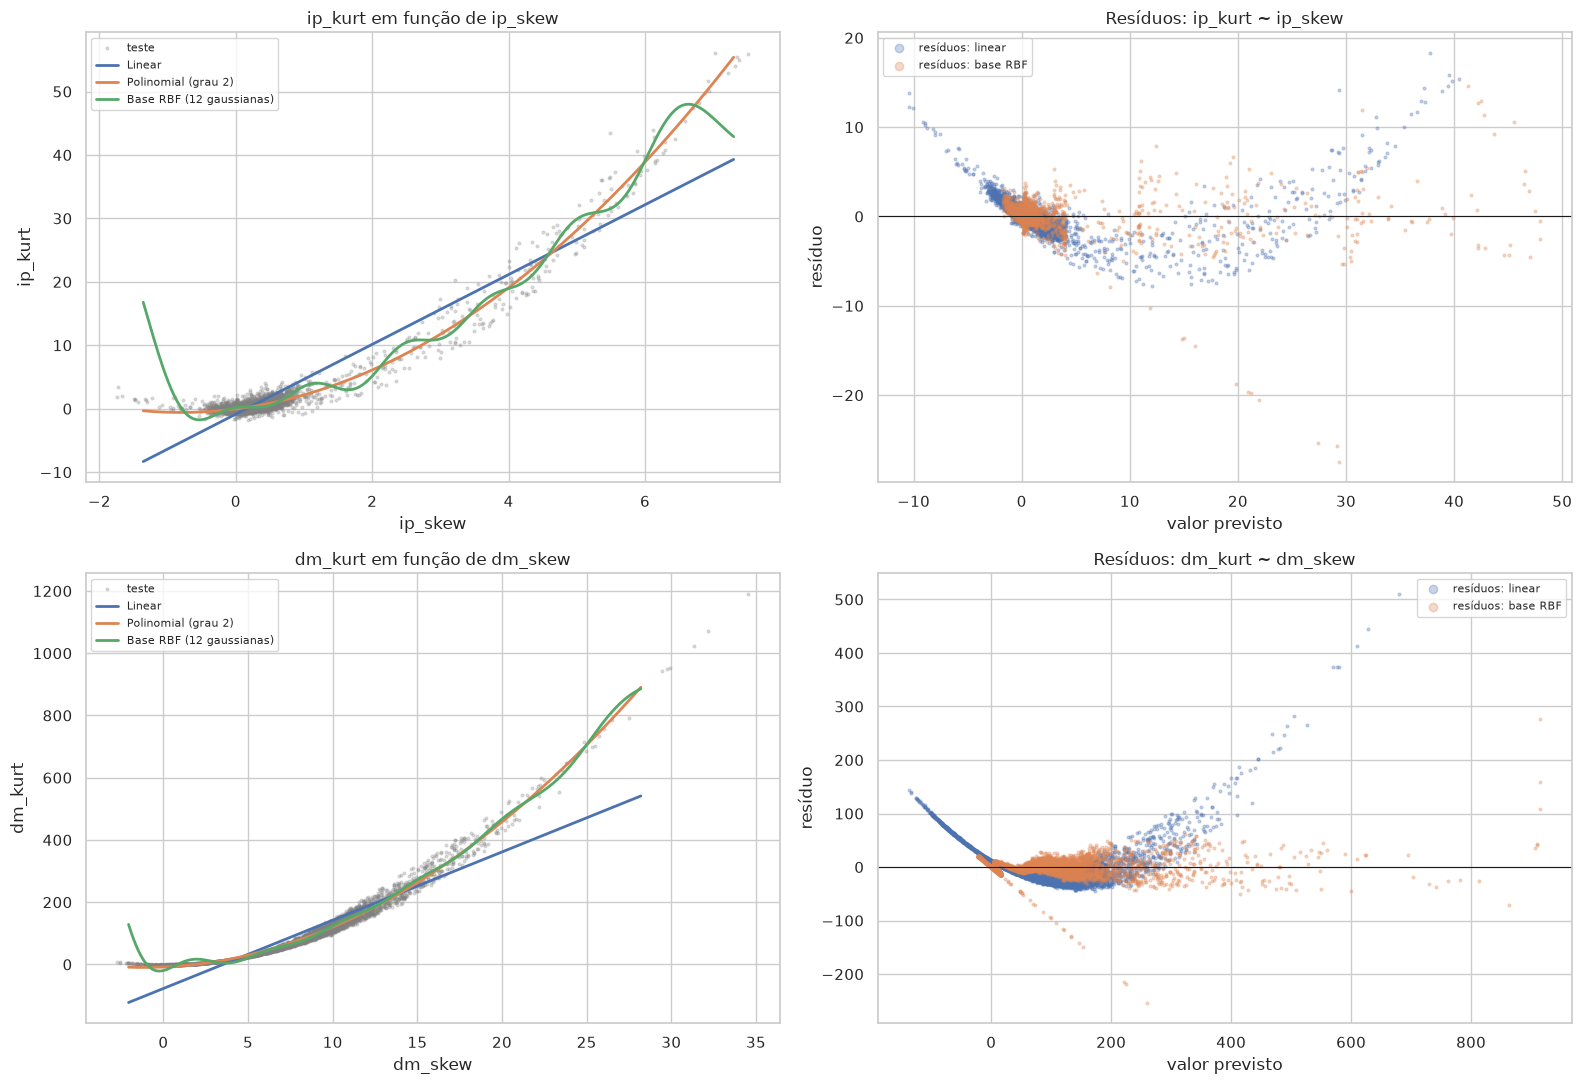

R2_teste                    \
y ~ x                    dm_kurt ~ dm_skew ip_kurt ~ ip_skew   
modelo                                                         
Base RBF (12 gaussianas)             0.973             0.933   
Linear                               0.845             0.889   
Polinomial (grau 2)                  0.985             0.978   

                                 MSE_teste                    
y ~ x                    dm_kurt ~ dm_skew ip_kurt ~ ip_skew  
modelo                                                        
Base RBF (12 gaussianas)           292.916             2.526  
Linear                           1,707.689             4.149  
Polinomial (grau 2)                161.080             0.837

In [4]:
class RBFBasis(BaseEstimator, TransformerMixin):
    # base de funções gaussianas 1D: phi_j(x) = exp(-(x - c_j)^2 / (2 s^2))
    def __init__(self, n_centers=12):
        self.n_centers = n_centers
    def fit(self, X, y=None):
        x = np.asarray(X, dtype=float).ravel()
        lo, hi = np.quantile(x, [0.005, 0.995])
        self.centers_ = np.linspace(lo, hi, self.n_centers)
        self.width_ = (hi - lo) / (self.n_centers - 1)
        return self
    def transform(self, X):
        x = np.asarray(X, dtype=float).reshape(-1, 1)
        return np.exp(-((x - self.centers_) ** 2) / (2 * self.width_ ** 2))

reg_models = {
    "Linear": make_pipeline(LinearRegression()),
    "Polinomial (grau 2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Base RBF (12 gaussianas)": make_pipeline(RBFBasis(12), LinearRegression()),
}
pairs = [("ip_skew", "ip_kurt"), ("dm_skew", "dm_kurt")]   # (x, y)

reg_rows = []
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for i, (xc, yc) in enumerate(pairs):
    x_tr, x_te = Xp_tr[[xc]].values, Xp_te[[xc]].values
    t_tr, t_te = Xp_tr[yc].values, Xp_te[yc].values
    ax_fit, ax_res = axes[i]
    ax_fit.scatter(x_te, t_te, s=4, alpha=0.25, c="gray", label="teste")
    grid = np.linspace(np.quantile(x_tr, 0.001), np.quantile(x_tr, 0.999), 400).reshape(-1, 1)
    for name, m in reg_models.items():
        m = clone(m).fit(x_tr, t_tr)
        pred = m.predict(x_te)
        reg_rows.append({"y ~ x": f"{yc} ~ {xc}", "modelo": name,
                         "R2_teste": r2_score(t_te, pred), "MSE_teste": mean_squared_error(t_te, pred)})
        ax_fit.plot(grid, m.predict(grid), lw=2, label=name)
        if name == "Linear":
            ax_res.scatter(pred, t_te - pred, s=4, alpha=0.3, label="resíduos: linear")
        if name.startswith("Base RBF"):
            ax_res.scatter(pred, t_te - pred, s=4, alpha=0.3, label="resíduos: base RBF")
    ax_fit.set(xlabel=xc, ylabel=yc, title=f"{yc} em função de {xc}")
    ax_fit.legend(fontsize=8)
    ax_res.axhline(0, c="k", lw=0.8)
    ax_res.set(xlabel="valor previsto", ylabel="resíduo", title=f"Resíduos: {yc} ~ {xc}")
    ax_res.legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

pd.DataFrame(reg_rows).pivot(index="modelo", columns="y ~ x", values=["R2_teste", "MSE_teste"])

**Como ler:** se o resíduo do modelo linear forma um padrão (um "U" ou um leque), a relação não é linear, e a base polinomial ou RBF deve reduzir o MSE. Um R² alto **não** prova linearidade: um r = 0,95 pode esconder uma curva.

**Leitura física:** curtose e assimetria do mesmo perfil medem praticamente a mesma coisa, ou seja, quão concentrado e unilateral é o pico. Para os classificadores isso é **redundância**, o que afeta Naive Bayes e os coeficientes da Logística (seções A2 e A7).

## A2. Comparação de classificadores (Aulas 1 a 5)

| Modelo | Aula | Por que entra |
|---|---|---|
| Logística | 2 | Fronteira linear e probabilística; teste direto da H3 |
| Fronteira gaussiana com covariância comum (LDA) | 1 e 3 | Gaussianas por classe com mesma Σ, o que dá **fronteira linear** |
| Fronteira gaussiana com covariâncias próprias (QDA) | 1 e 3 | Uma gaussiana multivariada (MLE) por classe, o que dá **fronteira quadrática** |
| Naive Bayes gaussiano | 3 | Versão "ingênua" da anterior: Σ diagonal (atributos independentes) |
| KNN e KNN ponderado | 3 | Não paramétrico, baseado só na geometria local |
| SVM linear (soft margin) | 4 | Margem máxima com hinge loss |
| SVM com kernel RBF | 4 | Fronteira não linear via kernel trick |
| MLP | 2 | Rede neural, "caixa-preta" não linear |
| Random Forest | 5 | **Referência** não linear forte (não há atributos categóricos) |

Variantes com **Yeo-Johnson** (`PowerTransformer`) testam se "gaussianizar" as caudas longas ajuda os modelos que assumem normalidade (NB, QDA).

Nenhum modelo usa `class_weight` nesta comparação, para que as métricas de limiar sejam comparáveis entre si. O efeito do desbalanceamento é tratado na seção A5.

A rodada leva alguns minutos; a SVM RBF e o MLP são os mais lentos.

In [ ]:
models_p = {
    "Logística":                 make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Gaussiana Σ comum (LDA)":   make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "Gaussiana Σ própria (QDA)": make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=1e-3)),
    "QDA + Yeo-Johnson":         make_pipeline(PowerTransformer(), QuadraticDiscriminantAnalysis(reg_param=1e-3)),
    "Naive Bayes":               make_pipeline(GaussianNB()),
    "Naive Bayes + Yeo-Johnson": make_pipeline(PowerTransformer(), GaussianNB()),
    "KNN (k=15)":                make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "KNN ponderado (k=15)":      make_pipeline(StandardScaler(), KNeighborsClassifier(15, weights="distance")),
    "SVM linear":                make_pipeline(StandardScaler(), LinearSVC(C=1.0, max_iter=20000)),
    "SVM RBF":                   make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
    "MLP (32-16)":               make_pipeline(StandardScaler(), MLPClassifier((32, 16), early_stopping=True,
                                                                           max_iter=500, random_state=RANDOM_STATE)),
    "Random Forest":             RandomForestClassifier(300, min_samples_leaf=2, n_jobs=-1,
                                                        random_state=RANDOM_STATE),
}
res_p = run_cv(models_p, Xp_tr, yp_tr)
show_table(res_p)

ok  Logística                                AUC_ROC=0.976  AUC_PR=0.922


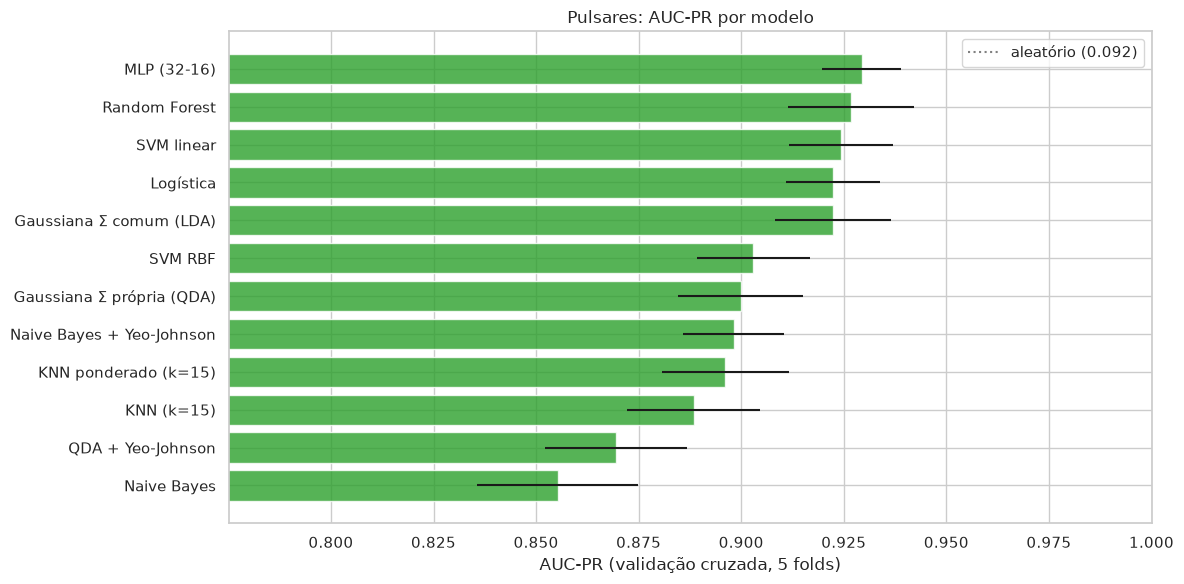

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
order = res_p.sort_values("AUC_PR").index
ax.barh(order, res_p.loc[order, "AUC_PR"], xerr=res_p.loc[order, "AUC_PR_dp"], color="tab:green", alpha=0.8)
ax.axvline(yp_tr.mean(), ls=":", c="gray", label=f"aleatório ({yp_tr.mean():.3f})")
ax.set(xlabel="AUC-PR (validação cruzada, 5 folds)", title="Pulsares: AUC-PR por modelo")
ax.set_xlim(max(0, res_p["AUC_PR"].min() - 0.08), 1)
ax.legend(); plt.tight_layout(); plt.show()

## A3. Margem rígida vs. margem suave

A SVM de margem rígida só existe se as classes forem **linearmente separáveis**. Na prática, ela equivale ao limite C → ∞ da margem suave. Varremos C e acompanhamos:
- a **largura da margem** 2/‖w‖;
- quantos pontos de treino **violam a margem** (y·f(x) < 1);
- a AUC em validação cruzada.

Se as violações não chegarem a zero mesmo com C enorme, os dados **não são linearmente separáveis** e a margem rígida não tem solução. Isso não contradiz a H3, que fala em separação *aproximada*.

*Nota técnica:* o `LinearSVC` usa a hinge loss **ao quadrado** (variante mais estável numericamente da vista em aula); o comportamento qualitativo é o mesmo.

,largura_margem (2/‖w‖),violações (y·f<1),erros de treino (y·f<0),AUC_ROC_cv
C,,,,
0.001,3.485,7373,387,0.975
0.010,2.019,4271,352,0.976
0.100,1.224,3371,326,0.977
1.000,1.082,3178,313,0.977
10.000,1.067,3160,310,0.977
100.000,1.065,3153,310,0.977
"1,000.000",1.065,3153,310,0.977


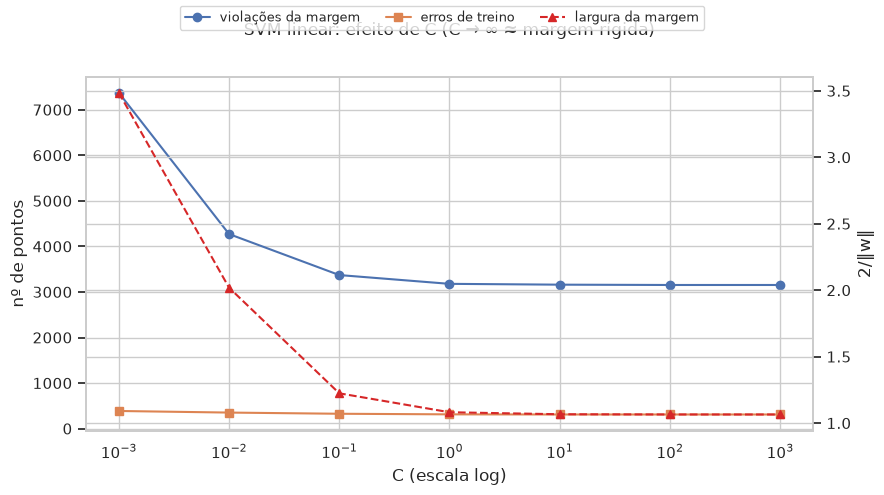

In [ ]:
Cs = [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]
rows = []
y_pm = np.where(yp_tr == 1, 1, -1)
for c_val in Cs:
    m = make_pipeline(StandardScaler(), LinearSVC(C=c_val, max_iter=50000)).fit(Xp_tr, yp_tr)
    w = m[-1].coef_.ravel()
    f = m.decision_function(Xp_tr)
    auc = cross_val_score(make_pipeline(StandardScaler(), LinearSVC(C=c_val, max_iter=50000)),
                          Xp_tr, yp_tr, cv=CV, scoring="roc_auc", n_jobs=-1).mean()
    rows.append({"C": c_val, "largura_margem (2/‖w‖)": 2 / np.linalg.norm(w),
                 "violações (y·f<1)": int((y_pm * f < 1).sum()),
                 "erros de treino (y·f<0)": int((y_pm * f < 0).sum()),
                 "AUC_ROC_cv": auc})
margin_df = pd.DataFrame(rows).set_index("C")
display(margin_df)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.semilogx(margin_df.index, margin_df["violações (y·f<1)"], "o-", label="violações da margem")
ax1.semilogx(margin_df.index, margin_df["erros de treino (y·f<0)"], "s-", label="erros de treino")
ax1.set(xlabel="C (escala log)", ylabel="nº de pontos")
ax2 = ax1.twinx()
ax2.semilogx(margin_df.index, margin_df["largura_margem (2/‖w‖)"], "^--", c="tab:red", label="largura da margem")
ax2.set_ylabel("2/‖w‖")
fig.legend(loc="upper center", ncol=3, fontsize=9)
ax1.set_title("SVM linear: efeito de C (C → ∞ ≈ margem rígida)", pad=30)
plt.tight_layout(); plt.show()

## A4. Avaliação no conjunto de teste

Treinamos cada modelo no treino inteiro e avaliamos uma única vez no teste (20% separados no início).

,AUC_ROC,AUC_PR,recall,precisão,FN (pulsares perdidos),FP (alarmes falsos)
modelo,,,,,,
SVM linear,0.972,0.933,0.814,0.960,61,11
Logística,0.971,0.933,0.826,0.944,57,16
Random Forest,0.970,0.929,0.869,0.925,43,23
Gaussiana Σ comum (LDA),0.971,0.929,0.780,0.959,72,11
MLP (32-16),0.971,0.927,0.835,0.945,54,16
KNN ponderado (k=15),0.957,0.913,0.841,0.939,52,18
SVM RBF,0.954,0.908,0.835,0.948,54,15
KNN (k=15),0.957,0.907,0.841,0.945,52,16
Naive Bayes + Yeo-Johnson,0.957,0.901,0.878,0.796,40,74


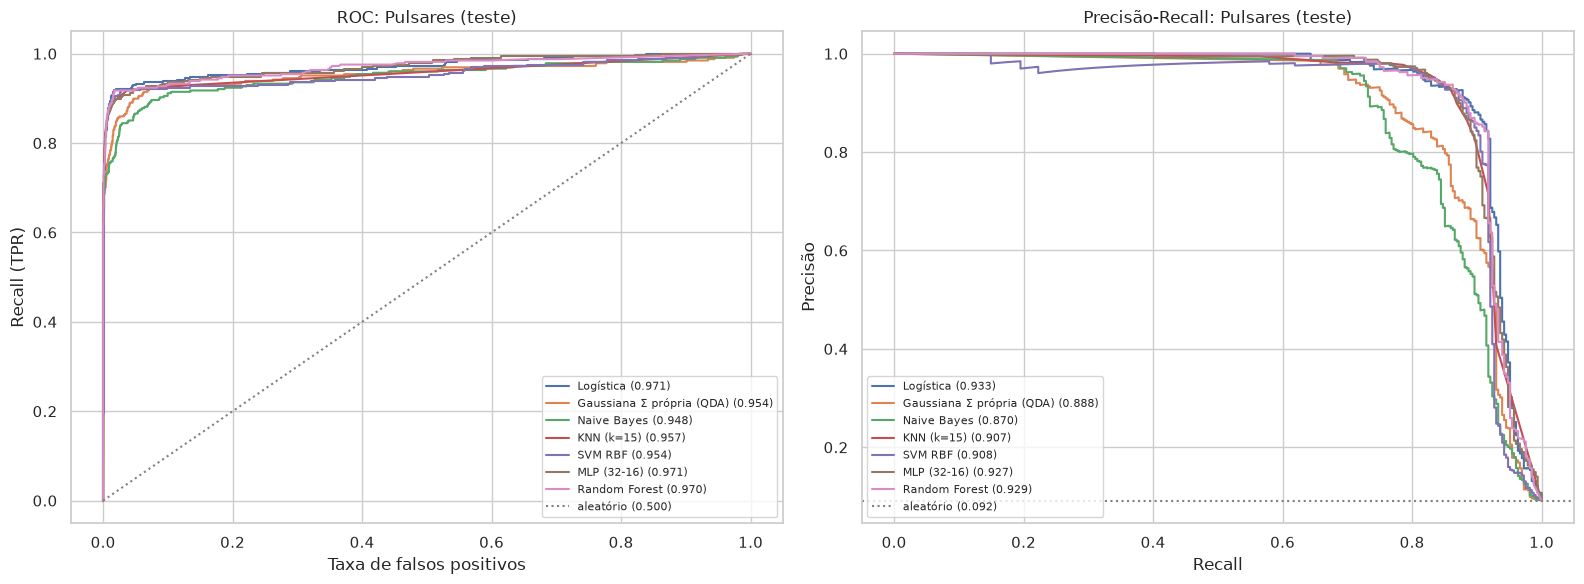

In [ ]:
fitted_p = {name: clone(m).fit(Xp_tr, yp_tr) for name, m in models_p.items()}

test_rows = []
for name, m in fitted_p.items():
    s = score_of(m, Xp_te); pred = m.predict(Xp_te)
    test_rows.append({"modelo": name, "AUC_ROC": roc_auc_score(yp_te, s),
                      "AUC_PR": average_precision_score(yp_te, s),
                      "recall": recall_score(yp_te, pred), "precisão": precision_score(yp_te, pred),
                      "FN (pulsares perdidos)": int(((pred == 0) & (yp_te == 1)).sum()),
                      "FP (alarmes falsos)": int(((pred == 1) & (yp_te == 0)).sum())})
test_p = pd.DataFrame(test_rows).set_index("modelo").sort_values("AUC_PR", ascending=False)
display(test_p)

selected = ["Logística", "Gaussiana Σ própria (QDA)", "Naive Bayes", "KNN (k=15)",
            "SVM RBF", "MLP (32-16)", "Random Forest"]
plot_curves({k: fitted_p[k] for k in selected}, Xp_te, yp_te, "Pulsares (teste)")

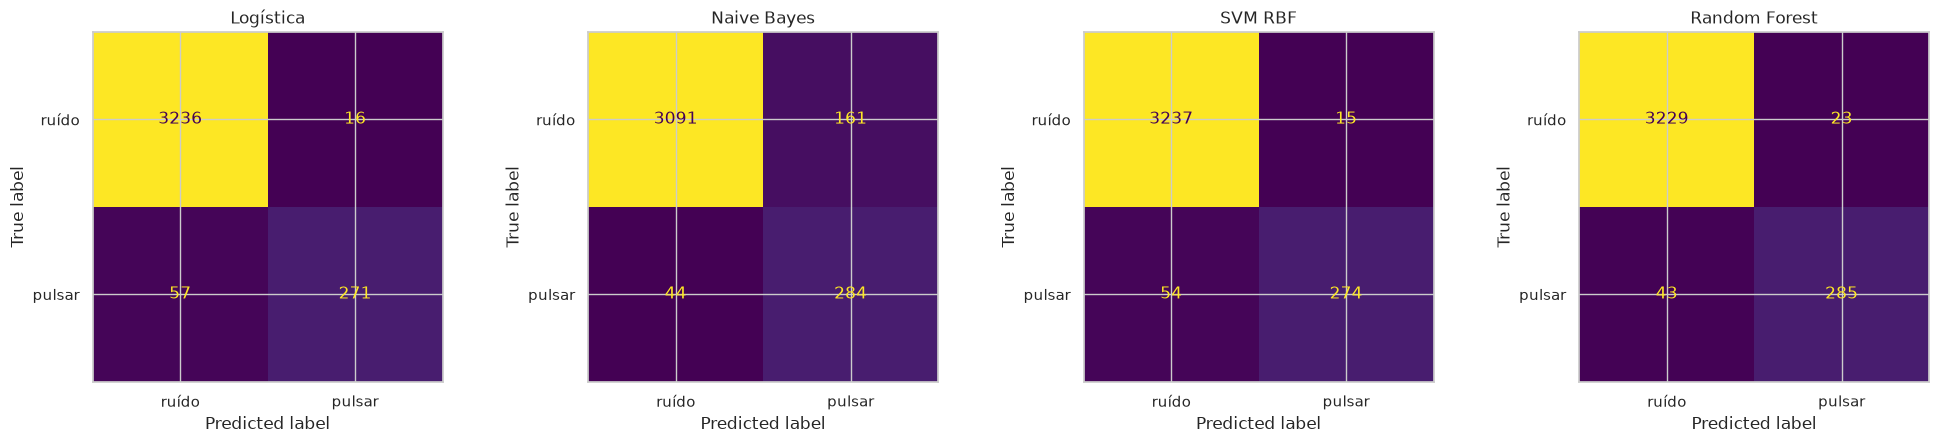

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, ["Logística", "Naive Bayes", "SVM RBF", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted_p[name], Xp_te, yp_te, ax=ax, colorbar=False,
                                          display_labels=["ruído", "pulsar"], values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

## A5. Desbalanceamento e escolha do limiar (H4)

No limiar padrão de 0,5, os modelos otimizam implicitamente a **acurácia**, que favorece a classe majoritária. Duas formas de priorizar o recall:
1. **Reponderar as classes** no treino (`class_weight="balanced"`);
2. **Mover o limiar de decisão** do modelo original.

O limiar é escolhido com previsões *out-of-fold* do **treino**, exigindo recall ≥ 0,95 com a maior precisão possível. Só depois aplicamos no teste. Escolher o limiar olhando o teste seria vazamento.

Melhor modelo por AUC-PR em CV: MLP (32-16)
Limiar escolhido no treino para recall ≥ 0.95: 0.0220


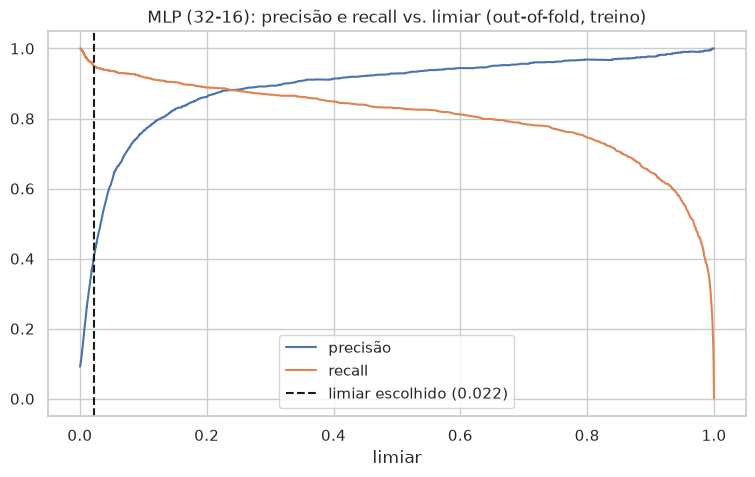

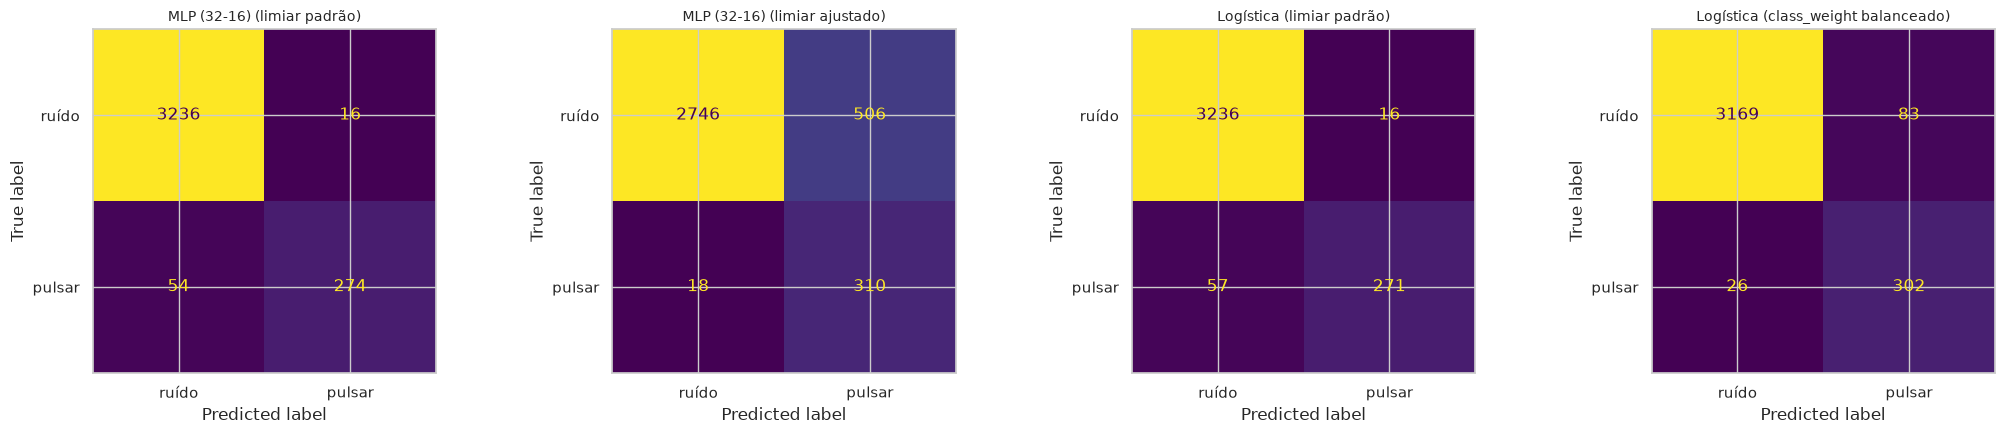

,recall,precisão,acurácia
variante,,,
MLP (32-16) (limiar padrão),0.835,0.945,0.980
MLP (32-16) (limiar ajustado),0.945,0.380,0.854
Logística (limiar padrão),0.826,0.944,0.980
Logística (class_weight balanceado),0.921,0.784,0.970


In [ ]:
TARGET_RECALL = 0.95
best_name = res_p["AUC_PR"].idxmax()
print("Melhor modelo por AUC-PR em CV:", best_name)

# limiar escolhido no treino (previsões out-of-fold)
method = "predict_proba" if hasattr(models_p[best_name], "predict_proba") else "decision_function"
oof = cross_val_predict(models_p[best_name], Xp_tr, yp_tr, cv=CV, method=method, n_jobs=-1)
oof = oof[:, 1] if oof.ndim == 2 else oof
prec, rec, thr = precision_recall_curve(yp_tr, oof)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
thr_star = thr[ok[np.argmax(prec[ok])]]
print(f"Limiar escolhido no treino para recall ≥ {TARGET_RECALL}: {thr_star:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thr, prec[:-1], label="precisão"); ax.plot(thr, rec[:-1], label="recall")
ax.axvline(thr_star, ls="--", c="k", label=f"limiar escolhido ({thr_star:.3f})")
ax.set(xlabel="limiar", title=f"{best_name}: precisão e recall vs. limiar (out-of-fold, treino)")
ax.legend(); plt.show()

# comparação no teste: padrão, class_weight balanceado (Logística) e limiar ajustado
m_best = fitted_p[best_name]
s_te = score_of(m_best, Xp_te)
default_thr = 0.5 if method == "predict_proba" else 0.0
variants = {
    f"{best_name} (limiar padrão)": (s_te >= default_thr).astype(int),
    f"{best_name} (limiar ajustado)": (s_te >= thr_star).astype(int),
    "Logística (limiar padrão)": fitted_p["Logística"].predict(Xp_te),
    "Logística (class_weight balanceado)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")
    ).fit(Xp_tr, yp_tr).predict(Xp_te),
}
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
summary = []
for ax, (name, pred) in zip(axes, variants.items()):
    ConfusionMatrixDisplay(confusion_matrix(yp_te, pred), display_labels=["ruído", "pulsar"]).plot(
        ax=ax, colorbar=False, values_format="d")
    ax.set_title(name, fontsize=10)
    summary.append({"variante": name, "recall": recall_score(yp_te, pred),
                    "precisão": precision_score(yp_te, pred),
                    "acurácia": (pred == yp_te).mean()})
plt.tight_layout(); plt.show()
pd.DataFrame(summary).set_index("variante")

**Anotações para o relatório sobre (H4):** compare a acurácia com o recall em cada variante. Aumentar o recall de ~0,85 para ~0,95 custa poucos pontos de acurácia, mas multiplica os alarmes falsos. A escolha do ponto de operação é uma **decisão do problema**, não do modelo: num levantamento astronômico, um falso positivo custa uns segundos de inspeção humana, enquanto um falso negativo é um pulsar que não será descoberto.

## A6. Testes diretos das hipóteses H2 e H3

- **H2 (IP separa melhor que DM):** mesmos modelos treinados só com os atributos IP, só com os DM, e com todos.
- **H3 (separação quase linear):** melhor modelo linear vs. melhor não linear. Incluímos também uma Logística usando **só a 1ª componente principal** (PC1 da PCA), para medir quanto da separação está numa única direção.

In [ ]:
IP = [c for c in FEATURES if c.startswith("ip")]
DM = [c for c in FEATURES if c.startswith("dm")]
h2_models = {"Logística": models_p["Logística"], "SVM RBF": models_p["SVM RBF"],
             "Random Forest": models_p["Random Forest"]}
rows = []
for set_name, cols in [("só IP", IP), ("só DM", DM), ("todos", FEATURES)]:
    for name, m in h2_models.items():
        r = cross_validate(m, Xp_tr[cols], yp_tr, cv=CV, n_jobs=-1,
                           scoring={"AUC_ROC": "roc_auc", "AUC_PR": "average_precision"})
        rows.append({"atributos": set_name, "modelo": name,
                     "AUC_ROC": r["test_AUC_ROC"].mean(), "AUC_PR": r["test_AUC_PR"].mean()})
h2 = pd.DataFrame(rows)
display(h2.pivot(index="modelo", columns="atributos", values=["AUC_ROC", "AUC_PR"]))

AUC_ROC             AUC_PR            
atributos       só DM só IP todos  só DM só IP todos
modelo                                              
Logística       0.885 0.973 0.976  0.350 0.913 0.922
Random Forest   0.933 0.968 0.974  0.782 0.913 0.927
SVM RBF         0.867 0.940 0.957  0.682 0.870 0.903

In [ ]:
pc1_model = make_pipeline(StandardScaler(), PCA(n_components=1), LogisticRegression())
pc1 = cross_validate(pc1_model, Xp_tr, yp_tr, cv=CV, scoring={"AUC_ROC": "roc_auc", "AUC_PR": "average_precision"})

linear = ["Logística", "Gaussiana Σ comum (LDA)", "SVM linear"]
nonlinear = ["Gaussiana Σ própria (QDA)", "KNN (k=15)", "SVM RBF", "MLP (32-16)", "Random Forest"]
best_lin = res_p.loc[linear, "AUC_PR"].idxmax()
best_nl = res_p.loc[nonlinear, "AUC_PR"].idxmax()

h3 = pd.DataFrame({
    "Logística só com PC1": [pc1["test_AUC_ROC"].mean(), pc1["test_AUC_PR"].mean()],
    f"Melhor linear: {best_lin}": res_p.loc[best_lin, ["AUC_ROC", "AUC_PR"]].values,
    f"Melhor não linear: {best_nl}": res_p.loc[best_nl, ["AUC_ROC", "AUC_PR"]].values,
}, index=["AUC_ROC", "AUC_PR"]).T
display(h3)
gain = res_p.loc[best_nl, "AUC_PR"] - res_p.loc[best_lin, "AUC_PR"]
print(f"Ganho do melhor não linear sobre o melhor linear: {gain:+.3f} em AUC-PR "
      f"(desvio-padrão entre folds ≈ {res_p.loc[[best_lin, best_nl], 'AUC_PR_dp'].max():.3f})")

,AUC_ROC,AUC_PR
Logística só com PC1,0.956,0.842
Melhor linear: SVM linear,0.977,0.924
Melhor não linear: MLP (32-16),0.978,0.929


Ganho do melhor não linear sobre o melhor linear: +0.005 em AUC-PR (desvio-padrão entre folds ≈ 0.013)


**Critério de leitura da H3:** se o ganho do não linear for da ordem do desvio-padrão entre folds, a diferença não é significativa e a H3 se confirma: uma fronteira linear já captura quase toda a separação. Se a Logística só com a PC1 já chegar perto, isso confirma o que o gráfico da PCA sugeria no EDA.

## A7. Interpretação dos modelos (base do passo 6)

1. **Coeficientes da Logística**, com todos os atributos e com um subconjunto sem redundância. Com multicolinearidade, os coeficientes do modelo completo podem trocar de sinal e não devem ser lidos isoladamente.
2. **Importância por permutação** do melhor modelo no teste: quanto a AUC-PR cai quando embaralhamos cada atributo.
3. **Árvore rasa** (profundidade 3, critério de entropia): as regras mais simples que separam pulsar de ruído.
4. **Análise dos erros:** onde ficam os falsos negativos no plano da PCA.

,todos os atributos,sem redundância
dm_kurt,-0.326,NaN
dm_mean,-0.826,NaN
dm_skew,-0.202,-0.512
dm_std,0.881,0.205
ip_kurt,-3.051,NaN
ip_mean,0.576,0.591
ip_skew,6.081,4.422
ip_std,-0.125,0.088


AUC_PR (CV) com subconjunto reduzido: 0.921


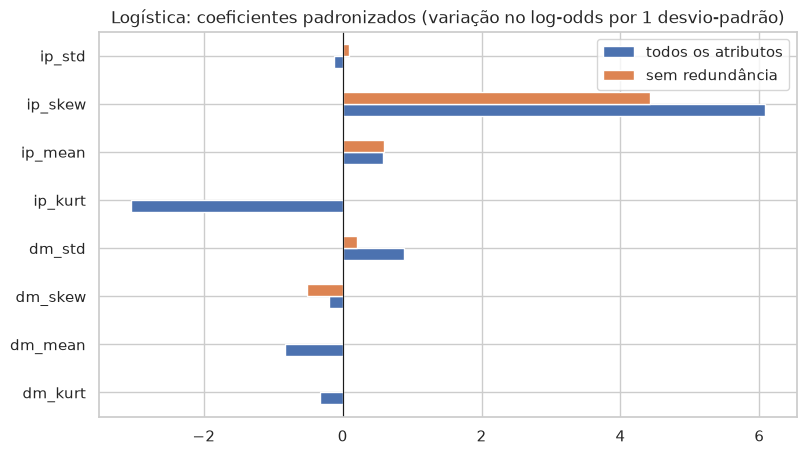

In [ ]:
def logit_coefs(cols):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xp_tr[cols], yp_tr)
    return pd.Series(m[-1].coef_.ravel(), index=cols)

reduced = ["ip_mean", "ip_std", "ip_skew", "dm_std", "dm_skew"]   # um representante por par redundante
coefs = pd.DataFrame({"todos os atributos": logit_coefs(FEATURES),
                      "sem redundância": logit_coefs(reduced)})
display(coefs.round(3))
print("AUC_PR (CV) com subconjunto reduzido:",
      cross_val_score(models_p["Logística"], Xp_tr[reduced], yp_tr, cv=CV,
                      scoring="average_precision").mean().round(3))

coefs.plot(kind="barh", figsize=(9, 5))
plt.axvline(0, c="k", lw=0.8)
plt.title("Logística: coeficientes padronizados (variação no log-odds por 1 desvio-padrão)")
plt.show()

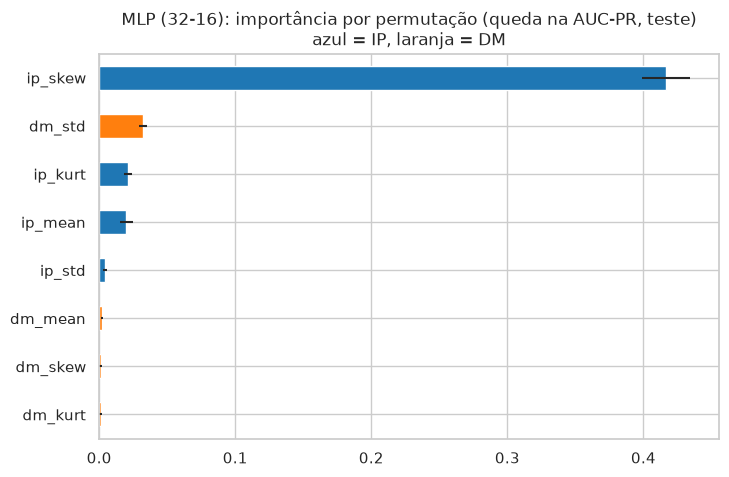

In [ ]:
pi = permutation_importance(fitted_p[best_name], Xp_te, yp_te, scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.index],
         figsize=(8, 5), color=["tab:blue" if c.startswith("ip") else "tab:orange" for c in imp.index])
plt.title(f"{best_name}: importância por permutação (queda na AUC-PR, teste)\nazul = IP, laranja = DM")
plt.show()

AUC_ROC da árvore rasa no teste: 0.976
|--- ip_skew <= 1.11
|   |--- ip_skew <= 0.35
|   |   |--- ip_skew <= 0.09
|   |   |   |--- class: 0
|   |   |--- ip_skew >  0.09
|   |   |   |--- class: 0
|   |--- ip_skew >  0.35
|   |   |--- dm_std <= 27.65
|   |   |   |--- class: 0
|   |   |--- dm_std >  27.65
|   |   |   |--- class: 0
|--- ip_skew >  1.11
|   |--- ip_skew <= 1.54
|   |   |--- dm_std <= 23.41
|   |   |   |--- class: 0
|   |   |--- dm_std >  23.41
|   |   |   |--- class: 1
|   |--- ip_skew >  1.54
|   |   |--- ip_skew <= 2.67
|   |   |   |--- class: 1
|   |   |--- ip_skew >  2.67
|   |   |   |--- class: 1



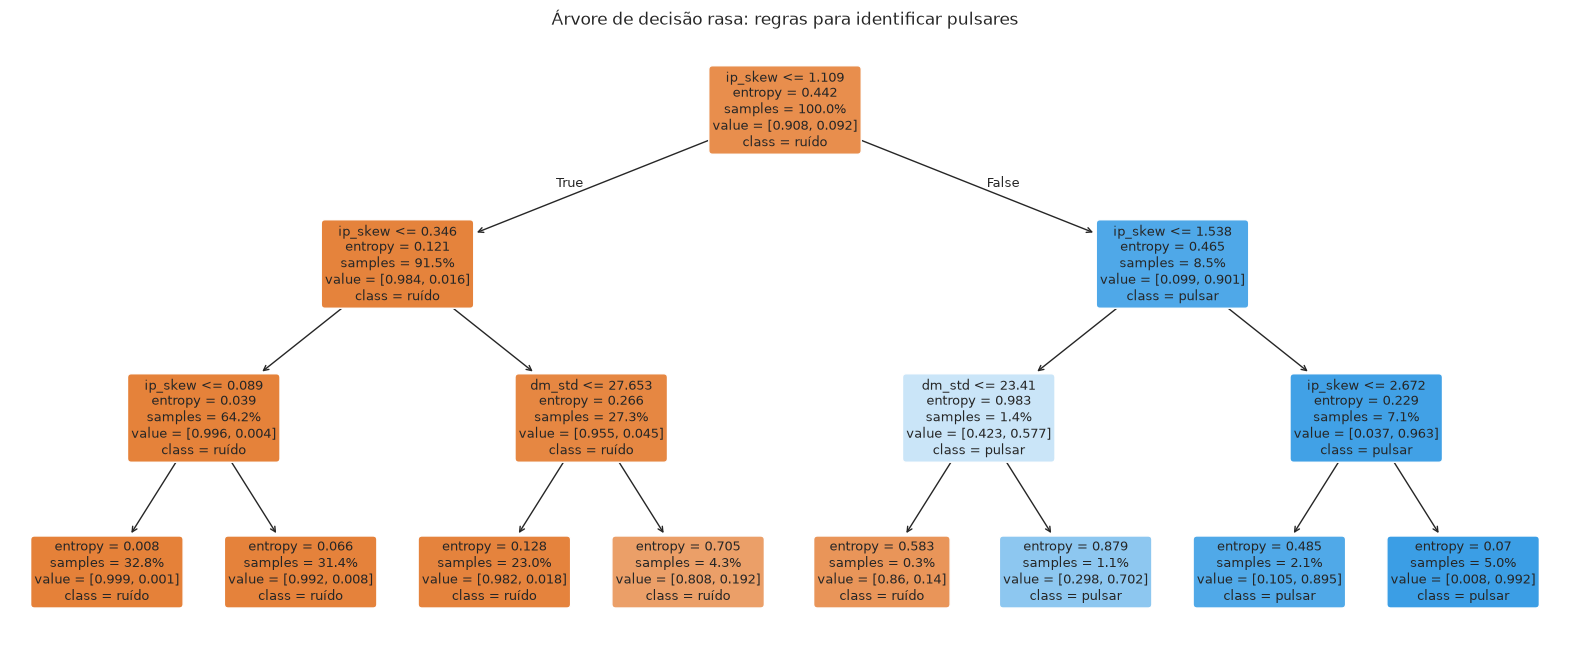

In [ ]:
tree_p = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=RANDOM_STATE).fit(Xp_tr, yp_tr)
print("AUC_ROC da árvore rasa no teste:", round(roc_auc_score(yp_te, tree_p.predict_proba(Xp_te)[:, 1]), 3))
print(export_text(tree_p, feature_names=FEATURES, decimals=2))
plt.figure(figsize=(20, 8))
plot_tree(tree_p, feature_names=FEATURES, class_names=["ruído", "pulsar"], filled=True,
          rounded=True, proportion=True, fontsize=9)
plt.title("Árvore de decisão rasa: regras para identificar pulsares")
plt.show()

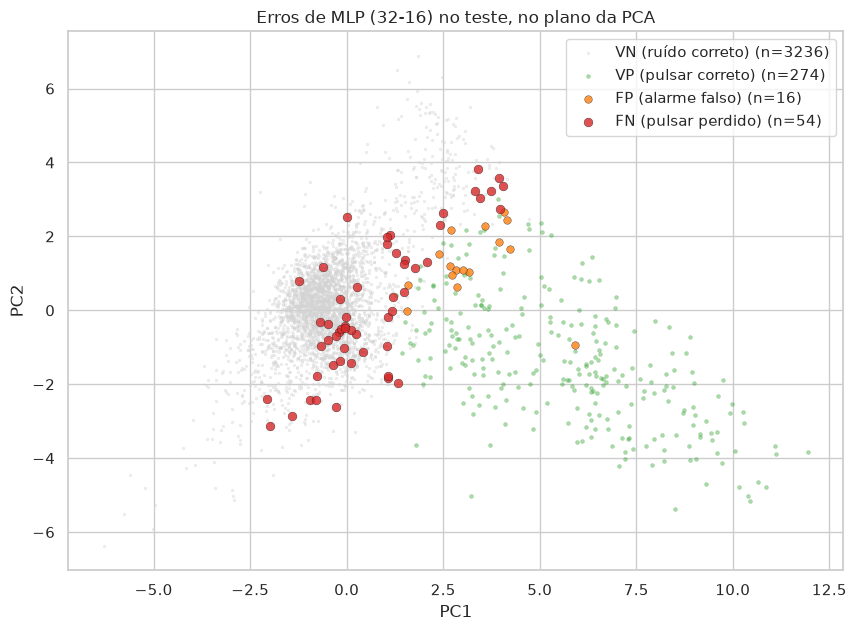

,ip_mean,ip_std,ip_kurt,ip_skew,dm_mean,dm_std,dm_kurt,dm_skew
grupo,,,,,,,,
FN (pulsar perdido),99.164,44.789,0.897,0.679,3.027,20.941,69.678,8.113
FP (alarme falso),87.340,45.853,3.135,1.356,55.725,69.426,0.149,1.162
VN (ruído correto),117.223,47.568,0.123,0.180,2.658,17.725,90.192,8.736
VP (pulsar correto),42.844,36.157,15.974,3.590,42.709,62.642,1.446,1.570


In [ ]:
# onde o melhor modelo erra? projeção no plano PC1 x PC2 (PCA ajustada no treino)
pca_vis = make_pipeline(StandardScaler(), PCA(2)).fit(Xp_tr)
Z = pca_vis.transform(Xp_te)
pred_best = (s_te >= default_thr).astype(int)
groups = {"VN (ruído correto)": (yp_te == 0) & (pred_best == 0),
          "VP (pulsar correto)": (yp_te == 1) & (pred_best == 1),
          "FP (alarme falso)": (yp_te == 0) & (pred_best == 1),
          "FN (pulsar perdido)": (yp_te == 1) & (pred_best == 0)}
style = {"VN (ruído correto)": ("lightgray", 4), "VP (pulsar correto)": ("tab:green", 8),
         "FP (alarme falso)": ("tab:orange", 30), "FN (pulsar perdido)": ("tab:red", 40)}
plt.figure(figsize=(10, 7))
for g, mask in groups.items():
    c, s = style[g]
    plt.scatter(Z[mask, 0], Z[mask, 1], c=c, s=s, alpha=0.8 if s > 8 else 0.4,
                label=f"{g} (n={mask.sum()})", edgecolor="k" if s > 8 else None, linewidth=0.3)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.title(f"Erros de {best_name} no teste, no plano da PCA")
plt.show()

err = Xp_te.assign(grupo=np.select(list(groups.values()), list(groups.keys()), default="?"))
err.groupby("grupo")[FEATURES].median()

**Pergunta para o passo 6:** os falsos negativos se parecem mais com pulsares ou com ruído? Se as medianas deles ficarem próximas às dos VN, esses pulsares são **fracos ou atípicos** e nenhum modelo baseado nestes 8 atributos vai recuperá-los. O limite está nos **dados**, não no modelo, e a saída seria extrair novos atributos dos sinais brutos.

### Anotações da Parte A para o relatório (preenchidas em `CONCLUSOES.md`)
- **A1 (regressão):** Anotar regressões observadas
- **Melhor modelo e por quê:** Discussão acerca de métricas registradas
- **H2 (IP vs. DM)**
- **H3 (linear vs. não linear; margem rígida)**
- **H4 (limiar e desbalanceamento)**
- **Naive Bayes e redundância**
- **Perfil dos erros**

---
# Parte B: Meteoritos

Atributos contínuos (massa, ano, latitude, longitude) coexistem com categóricos (`fall`, `class_group`). Pela proposta:
- **regressão linear** para a relação entre os contínuos (B2);
- **classificação** de `fall` a partir dos atributos (B3);
- **árvores** sobre os atributos categóricos (B5).

**Decisão de recorte:** toda a modelagem de `fall` é feita **sem a Antártida**, porque ali o rótulo é trivialmente *Found* (H2).

In [ ]:
# CSV em docs/ (local) ou upload manual (Colab)
cands = sorted(glob.glob("Meteorite_Landings*.csv") + glob.glob("docs/Meteorite_Landings.csv"))
if not cands:
    from google.colab import files
    files.upload()
    cands = sorted(glob.glob("Meteorite_Landings*.csv"))
meteor_raw = pd.read_csv(cands[0])
print("Arquivo:", cands[0], meteor_raw.shape)

meteor = meteor_raw.rename(columns={"mass (g)": "mass_g", "reclat": "lat", "reclong": "lon"})
meteor["year"] = pd.to_numeric(meteor["year"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")

clean = meteor[meteor["nametype"] == "Valid"].copy()
clean.loc[(clean["lat"] == 0) & (clean["lon"] == 0), ["lat", "lon"]] = np.nan
clean.loc[(clean["lon"] < -180) | (clean["lon"] > 180), ["lat", "lon"]] = np.nan   # há longitude 354 no EDA
clean.loc[(clean["year"] < 860) | (clean["year"] > 2026), "year"] = np.nan
clean.loc[clean["mass_g"] <= 0, "mass_g"] = np.nan
clean["log_mass"] = np.log10(clean["mass_g"])
clean["fell"] = (clean["fall"] == "Fell").astype(int)

def class_group(c):
    c = str(c)
    if re.match(r"^(H|L|LL|H/L|L/LL|OC)(?![a-z])", c): return "Condrito ordinário"
    if re.match(r"^C(I|M|O|V|K|R|H|B)?(?![a-z])", c):  return "Condrito carbonáceo"
    if re.match(r"^E(H|L)?(?![a-z])", c):               return "Condrito enstatita"
    if re.match(r"^(R|K)(?![a-z])", c):                 return "Outros condritos (R, K)"
    if c.startswith("Iron"):                             return "Ferroso (Iron)"
    if c.startswith(("Pallasite", "Mesosiderite")):      return "Ferro-rochoso"
    if c.startswith(("Eucrite", "Howardite", "Diogenite", "Ureilite", "Aubrite", "Angrite",
                     "Acapulcoite", "Lodranite", "Winonaite", "Brachinite", "Martian", "Lunar",
                     "Shergottite", "Nakhlite", "Chassignite", "Achondrite", "Enst achon")):
        return "Acondrito"
    return "Outros/não classificado"
clean["class_group"] = clean["recclass"].map(class_group)

geo = clean.dropna(subset=["lat", "lon"]).copy()
geo["antarctica"] = geo["lat"] < -60
fora = geo[~geo["antarctica"]].copy()
print(f"Georreferenciados: {len(geo)} | Antártida: {geo['antarctica'].sum()} | fora: {len(fora)}")
print(f"Prevalência de Fell fora da Antártida: {fora['fell'].mean():.3f}")

Arquivo: docs/Meteorite_Landings.csv (45716, 10)
Georreferenciados: 32116 | Antártida: 22096 | fora: 10020
Prevalência de Fell fora da Antártida: 0.109


## B1. Pendências do EDA: H2 (massa), H3 e H4 sem a Antártida, e o tempo (H1)

In [ ]:
from scipy.stats import mannwhitneyu

print("H2: massa (log10 g) dentro e fora da Antártida")
display(geo.groupby("antarctica")["log_mass"].describe())

print("H3: massa mediana por tipo de registro, FORA da Antártida")
med = fora.groupby("fall")["log_mass"].median()
display(med.to_frame("mediana log10(g)").assign(**{"massa mediana (g)": 10 ** med}))
a = fora.loc[fora["fell"] == 1, "log_mass"].dropna(); b = fora.loc[fora["fell"] == 0, "log_mass"].dropna()
u = mannwhitneyu(a, b, alternative="greater")
print(f"Mann-Whitney (Fell > Found): U = {u.statistic:,.0f}, p = {u.pvalue:.2e}")
print(f"Correlação log_mass x fell fora da Antártida: r = {fora[['log_mass', 'fell']].corr().iloc[0, 1]:.2f}")

H2: massa (log10 g) dentro e fora da Antártida


,count,mean,std,min,25%,50%,75%,max
antarctica,,,,,,,,
False,"9,953.000",2.640,1.125,-1.000,1.925,2.543,3.301,7.778
True,"22,094.000",1.180,0.823,-2.000,0.591,1.129,1.692,5.610


H3: massa mediana por tipo de registro, FORA da Antártida


,mediana log10(g),massa mediana (g)
fall,,
Fell,3.463,"2,904.996"
Found,2.444,278.000


Mann-Whitney (Fell > Found): U = 7,013,928, p = 4.73e-147
Correlação log_mass x fell fora da Antártida: r = 0.24


global       sem Antártida      
fall                      Fell Found          Fell Found
class_group                                             
Acondrito                0.077 0.031         0.077 0.039
Condrito carbonáceo      0.040 0.025         0.040 0.024
Condrito enstatita       0.016 0.012         0.016 0.004
Condrito ordinário       0.775 0.894         0.775 0.828
Ferro-rochoso            0.010 0.006         0.010 0.014
Ferroso (Iron)           0.044 0.029         0.044 0.088
Outros condritos (R, K)  0.002 0.001         0.002 0.002
Outros/não classificado  0.037 0.001         0.037 0.002

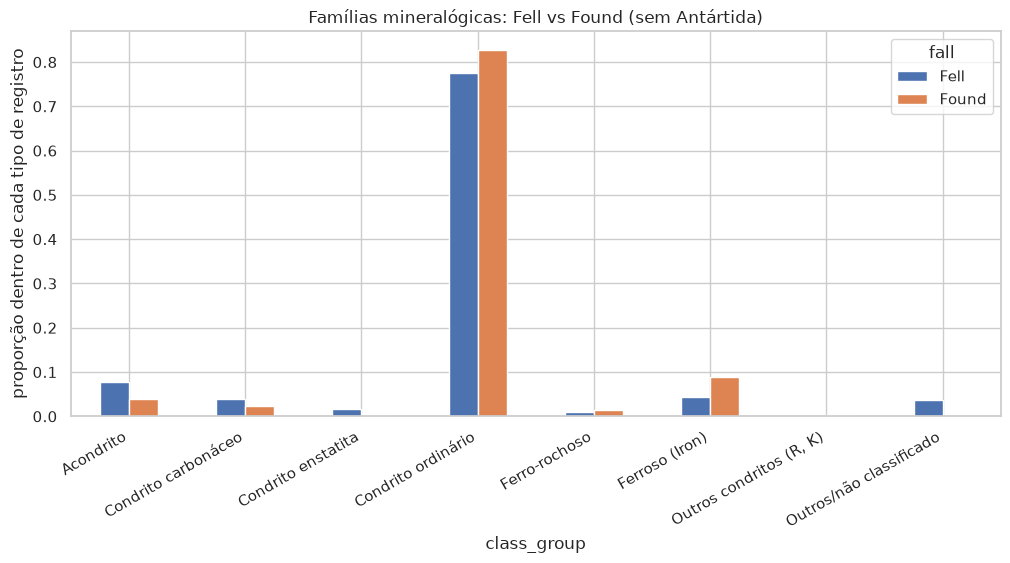

Iron entre Found: 0.029 global → 0.088 sem Antártida | entre Fell: 0.044


In [ ]:
# H4 sem Antártida
ct_all = pd.crosstab(geo["class_group"], geo["fall"], normalize="columns")
ct_out = pd.crosstab(fora["class_group"], fora["fall"], normalize="columns")
cmp = pd.concat({"global": ct_all, "sem Antártida": ct_out}, axis=1).round(3)
display(cmp)

ct_out.plot(kind="bar", figsize=(12, 5))
plt.ylabel("proporção dentro de cada tipo de registro")
plt.title("Famílias mineralógicas: Fell vs Found (sem Antártida)")
plt.xticks(rotation=30, ha="right"); plt.show()

iron = cmp.loc["Ferroso (Iron)"]
print(f"Iron entre Found: {iron[('global', 'Found')]:.3f} global → {iron[('sem Antártida', 'Found')]:.3f} sem Antártida "
      f"| entre Fell: {iron[('sem Antártida', 'Fell')]:.3f}")

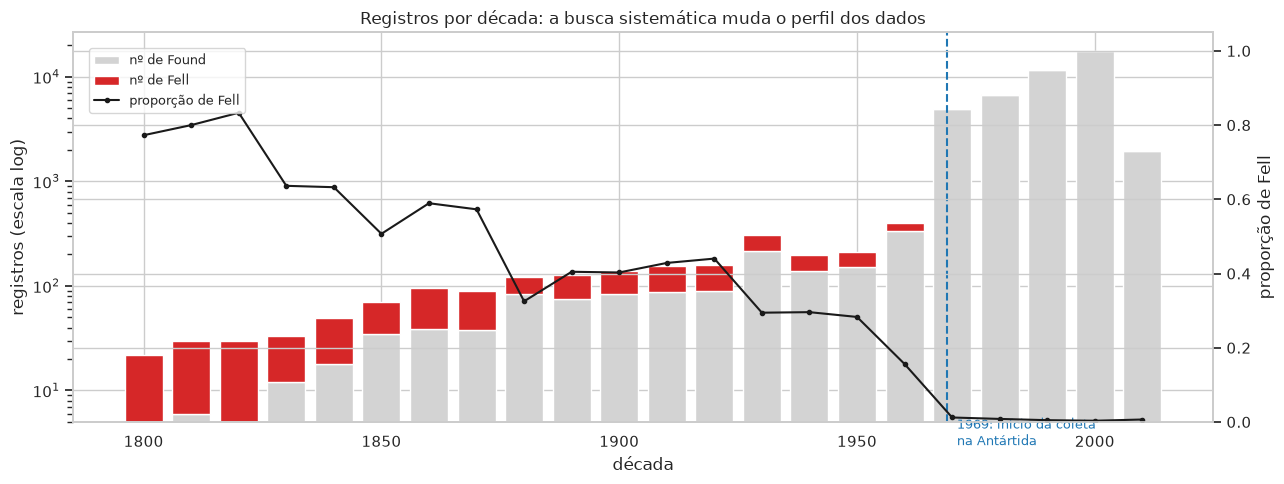

In [ ]:
# H1 temporal: proporção de Fell e volume de Found por década
dec = clean.dropna(subset=["year"]).assign(decada=lambda d: (d["year"] // 10 * 10).astype(int))
dec = dec[dec["decada"] >= 1800]
by_dec = dec.groupby("decada").agg(n=("fell", "size"), n_fell=("fell", "sum"))
by_dec["n_found"] = by_dec["n"] - by_dec["n_fell"]
by_dec["prop_fell"] = by_dec["n_fell"] / by_dec["n"]

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(by_dec.index, by_dec["n_found"], width=8, color="lightgray", label="nº de Found")
ax1.bar(by_dec.index, by_dec["n_fell"], width=8, bottom=by_dec["n_found"], color="tab:red", label="nº de Fell")
ax1.set_yscale("log"); ax1.set(xlabel="década", ylabel="registros (escala log)")
ax2 = ax1.twinx()
ax2.plot(by_dec.index, by_dec["prop_fell"], "k-o", ms=3, label="proporção de Fell")
ax2.set_ylabel("proporção de Fell"); ax2.set_ylim(0, 1.05)
ax1.axvline(1969, ls="--", c="tab:blue"); ax1.text(1971, 3, "1969: início da coleta\nna Antártida", fontsize=9, color="tab:blue")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9), fontsize=9)
plt.title("Registros por década: a busca sistemática muda o perfil dos dados")
plt.tight_layout(); plt.show()

## B2. Regressão linear múltipla: o que explica a massa? (Aula 2)

Modelo (sem Antártida): `log10(massa) ~ fell + ano + família mineralógica`.

O coeficiente de `fell` mede quanto mais massivo é um meteorito visto caindo **mantendo ano e família constantes**. Como a variável resposta está em log10, um coeficiente β significa massa **10^β vezes maior**. Isso testa a H3 controlando os principais confundidores.

,coef,IC95_inf,IC95_sup,p,fator multiplicativo (10^coef)
Intercept,2.636,2.602,2.670,0.000,432.502
família: Acondrito,-0.150,-0.245,-0.056,0.002,0.707
família: Condrito carbonáceo,-0.132,-0.252,-0.011,0.032,0.738
família: Condrito enstatita,0.050,-0.228,0.328,0.725,1.122
família: Ferro-rochoso,0.784,0.615,0.952,0.000,6.075
família: Ferroso (Iron),1.326,1.245,1.407,0.000,21.189
"família: Outros condritos (R, K)",-0.461,-0.857,-0.065,0.023,0.346
família: Outros/não classificado,-0.449,-0.791,-0.107,0.010,0.356
fell,0.547,0.471,0.623,0.000,3.521
ano_c,-0.054,-0.060,-0.048,0.000,0.883


R² = 0.261 | n = 9813


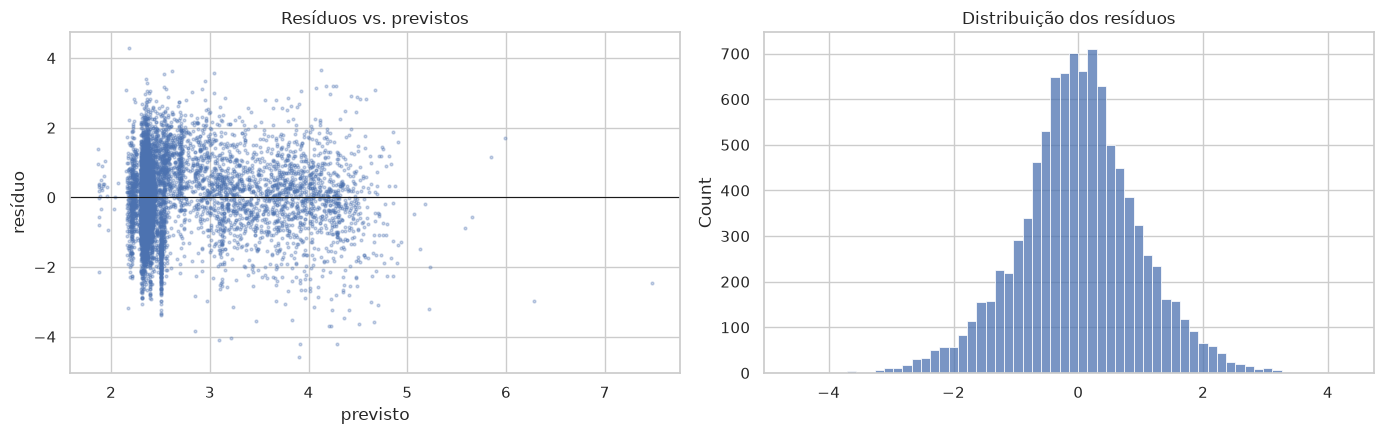

In [ ]:
import statsmodels.formula.api as smf

reg_df = fora.dropna(subset=["log_mass", "year"]).copy()
reg_df["ano_c"] = (reg_df["year"] - 1950) / 10   # ano centrado em 1950, em décadas
ols = smf.ols("log_mass ~ fell + ano_c + C(class_group, Treatment('Condrito ordinário'))",
              data=reg_df).fit()
coef_tab = pd.DataFrame({"coef": ols.params, "IC95_inf": ols.conf_int()[0],
                         "IC95_sup": ols.conf_int()[1], "p": ols.pvalues})
coef_tab["fator multiplicativo (10^coef)"] = 10 ** coef_tab["coef"]
coef_tab.index = coef_tab.index.str.replace(r"C\(class_group, Treatment\('Condrito ordinário'\)\)\[T\.", "família: ", regex=True).str.rstrip("]")
display(coef_tab)
print(f"R² = {ols.rsquared:.3f} | n = {int(ols.nobs)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(ols.fittedvalues, ols.resid, s=4, alpha=0.3)
axes[0].axhline(0, c="k", lw=0.8); axes[0].set(xlabel="previsto", ylabel="resíduo", title="Resíduos vs. previstos")
sns.histplot(ols.resid, bins=60, ax=axes[1]); axes[1].set_title("Distribuição dos resíduos")
plt.tight_layout(); plt.show()

**Como ler:** o R² deve ser baixo, porque a massa de um meteorito depende de muitas coisas que não estão nos dados (tamanho do corpo original, fragmentação na atmosfera). Isso não invalida o modelo: a pergunta aqui é o **sinal e o tamanho** do coeficiente de `fell`, e se ele sobrevive ao controle por ano e família.

## B3. Classificação de `fell`

Atributos: `log_mass`, `year`, `lat`, `lon` (contínuos) e `class_group` (categórico, one-hot).

Para separar **física do meteorito** de **condições de observação**, comparamos quatro conjuntos de atributos:
- **completo**;
- **sem ano**;
- **só o meteorito** (massa + família);
- **só o contexto** (ano + localização).

Se o "contexto" prever tão bem quanto o "completo", o modelo está aprendendo **quem estava olhando**, não propriedades do meteorito.

In [ ]:
NUM = ["log_mass", "year", "lat", "lon"]
CAT = ["class_group"]
mdf = fora.dropna(subset=NUM).reset_index(drop=True)
Xm, ym = mdf[NUM + CAT], mdf["fell"].values
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.2, stratify=ym, random_state=RANDOM_STATE)
print("Treino:", Xm_tr.shape, "prevalência", ym_tr.mean().round(3), "| Teste:", Xm_te.shape)

def prep(num, cat):
    parts = []
    if num: parts.append(("num", StandardScaler(), num))
    if cat: parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    return ColumnTransformer(parts)

def meteor_models(num, cat):
    return {
        "Logística":     make_pipeline(prep(num, cat), LogisticRegression(max_iter=5000)),
        "Árvore (prof. 6)": make_pipeline(prep(num, cat), DecisionTreeClassifier(
                              max_depth=6, criterion="entropy", min_samples_leaf=20, random_state=RANDOM_STATE)),
        "Bagging (200 árvores)": make_pipeline(prep(num, cat), BaggingClassifier(
                              DecisionTreeClassifier(min_samples_leaf=5), n_estimators=200,
                              n_jobs=-1, random_state=RANDOM_STATE)),
        "Random Forest":   make_pipeline(prep(num, cat), RandomForestClassifier(
                              300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
        "AdaBoost":        make_pipeline(prep(num, cat), AdaBoostClassifier(
                              n_estimators=300, learning_rate=0.5, random_state=RANDOM_STATE)),
    }

models_m = meteor_models(NUM, CAT)
res_m = run_cv(models_m, Xm_tr, ym_tr)
show_table(res_m)

Treino: (7850, 5) prevalência 0.108 | Teste: (1963, 5)
ok  Logística                                AUC_ROC=0.897  AUC_PR=0.714
ok  Árvore (prof. 6)                         AUC_ROC=0.953  AUC_PR=0.795
ok  Bagging (200 árvores)                    AUC_ROC=0.983  AUC_PR=0.881
ok  Random Forest                            AUC_ROC=0.984  AUC_PR=0.888
ok  AdaBoost                                 AUC_ROC=0.957  AUC_PR=0.783


,AUC_ROC,AUC_PR,recall,precisão,F1,acc_balanceada,acurácia,tempo_fit_s
modelo,,,,,,,,
Random Forest,0.984,0.888,0.729,0.871,0.793,0.858,0.959,0.957
Bagging (200 árvores),0.983,0.881,0.769,0.851,0.808,0.877,0.961,1.404
Árvore (prof. 6),0.953,0.795,0.728,0.786,0.755,0.852,0.949,0.025
AdaBoost,0.957,0.783,0.599,0.826,0.693,0.792,0.943,1.175
Logística,0.897,0.714,0.516,0.810,0.630,0.751,0.934,0.019


In [ ]:
feature_sets = {
    "completo":                   (NUM, CAT),
    "sem ano":                    (["log_mass", "lat", "lon"], CAT),
    "só meteorito (massa+família)": (["log_mass"], CAT),
    "só contexto (ano+local)":    (["year", "lat", "lon"], []),
}
rows = []
for set_name, (num, cat) in feature_sets.items():
    for name in ["Logística", "Random Forest"]:
        m = meteor_models(num, cat)[name]
        r = cross_validate(m, Xm_tr[num + cat], ym_tr, cv=CV, n_jobs=-1,
                           scoring={"AUC_ROC": "roc_auc", "AUC_PR": "average_precision"})
        rows.append({"atributos": set_name, "modelo": name,
                     "AUC_ROC": r["test_AUC_ROC"].mean(), "AUC_PR": r["test_AUC_PR"].mean()})
fs = pd.DataFrame(rows)
display(fs.pivot(index="atributos", columns="modelo", values=["AUC_ROC", "AUC_PR"])
          .loc[list(feature_sets)])
print(f"Referência aleatória para AUC-PR: {ym_tr.mean():.3f}")

AUC_ROC                  AUC_PR              
modelo                       Logística Random Forest Logística Random Forest
atributos                                                                   
completo                         0.897         0.984     0.714         0.888
sem ano                          0.785         0.982     0.459         0.858
só meteorito (massa+família)     0.773         0.764     0.333         0.323
só contexto (ano+local)          0.851         0.973     0.589         0.812

Referência aleatória para AUC-PR: 0.108


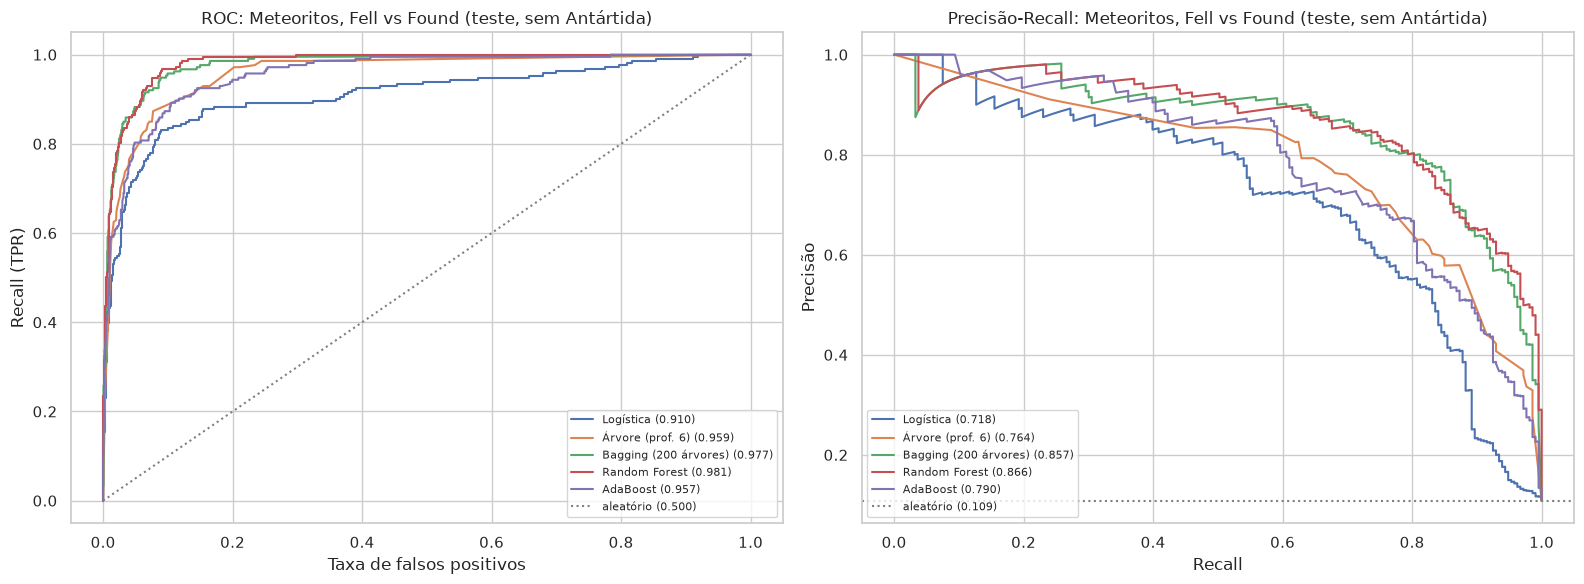

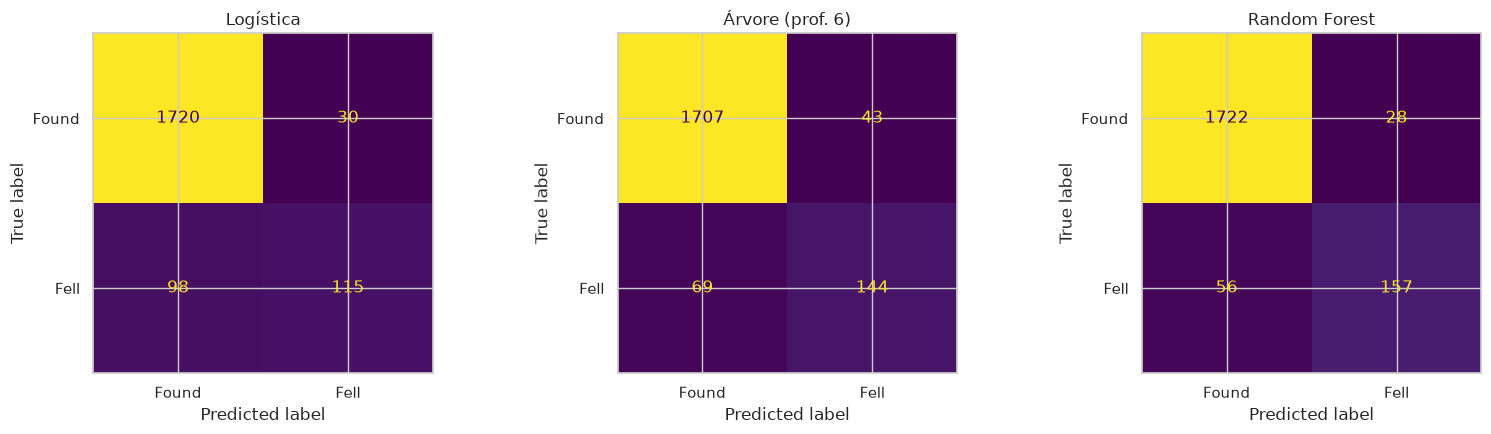

In [ ]:
fitted_m = {name: clone(m).fit(Xm_tr, ym_tr) for name, m in models_m.items()}
plot_curves(fitted_m, Xm_te, ym_te, "Meteoritos, Fell vs Found (teste, sem Antártida)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ["Logística", "Árvore (prof. 6)", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted_m[name], Xm_te, ym_te, ax=ax, colorbar=False,
                                          display_labels=["Found", "Fell"], values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

## B4. Interpretação: o que os modelos aprenderam?

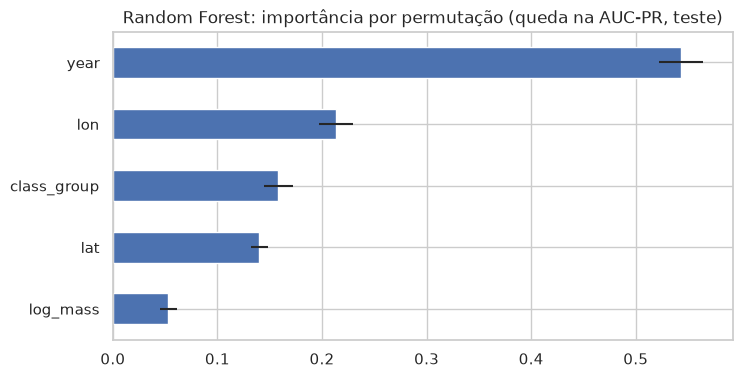

,odds ratio (×chance de ser Fell)
família: Ferroso (Iron),0.021
família: Ferro-rochoso,0.086
year,0.196
família: Condrito ordinário,1.294
"família: Outros condritos (R, K)",1.523
lat,1.726
log_mass,1.775
lon,1.982
família: Condrito carbonáceo,2.719
família: Acondrito,3.261


In [ ]:
# importância por permutação nas colunas ORIGINAIS
rf_m = fitted_m["Random Forest"]
pi_m = permutation_importance(rf_m, Xm_te, ym_te, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp_m = pd.Series(pi_m.importances_mean, index=NUM + CAT).sort_values()
imp_m.plot(kind="barh", xerr=pd.Series(pi_m.importances_std, index=NUM + CAT)[imp_m.index], figsize=(8, 4))
plt.title("Random Forest: importância por permutação (queda na AUC-PR, teste)")
plt.show()

# odds ratios da Logística (contínuos padronizados: efeito de +1 desvio-padrão)
lr_m = fitted_m["Logística"]
names = lr_m[0].get_feature_names_out()
odds = pd.Series(np.exp(lr_m[-1].coef_.ravel()), index=names).sort_values()
odds.index = odds.index.str.replace("num__", "").str.replace("cat__class_group_", "família: ")
display(odds.to_frame("odds ratio (×chance de ser Fell)").round(3))

AUC_ROC (teste): 0.922
|--- year <= 1967.50
|   |--- lon <= -68.78
|   |   |--- família=Ferroso (Iron) <= 0.50
|   |   |   |--- class: 0
|   |   |--- família=Ferroso (Iron) >  0.50
|   |   |   |--- class: 0
|   |--- lon >  -68.78
|   |   |--- família=Ferroso (Iron) <= 0.50
|   |   |   |--- class: 1
|   |   |--- família=Ferroso (Iron) >  0.50
|   |   |   |--- class: 0
|--- year >  1967.50
|   |--- log_mass <= 3.10
|   |   |--- lat <= 35.99
|   |   |   |--- class: 0
|   |   |--- lat >  35.99
|   |   |   |--- class: 0
|   |--- log_mass >  3.10
|   |   |--- lon <= 58.80
|   |   |   |--- class: 0
|   |   |--- lon >  58.80
|   |   |   |--- class: 0



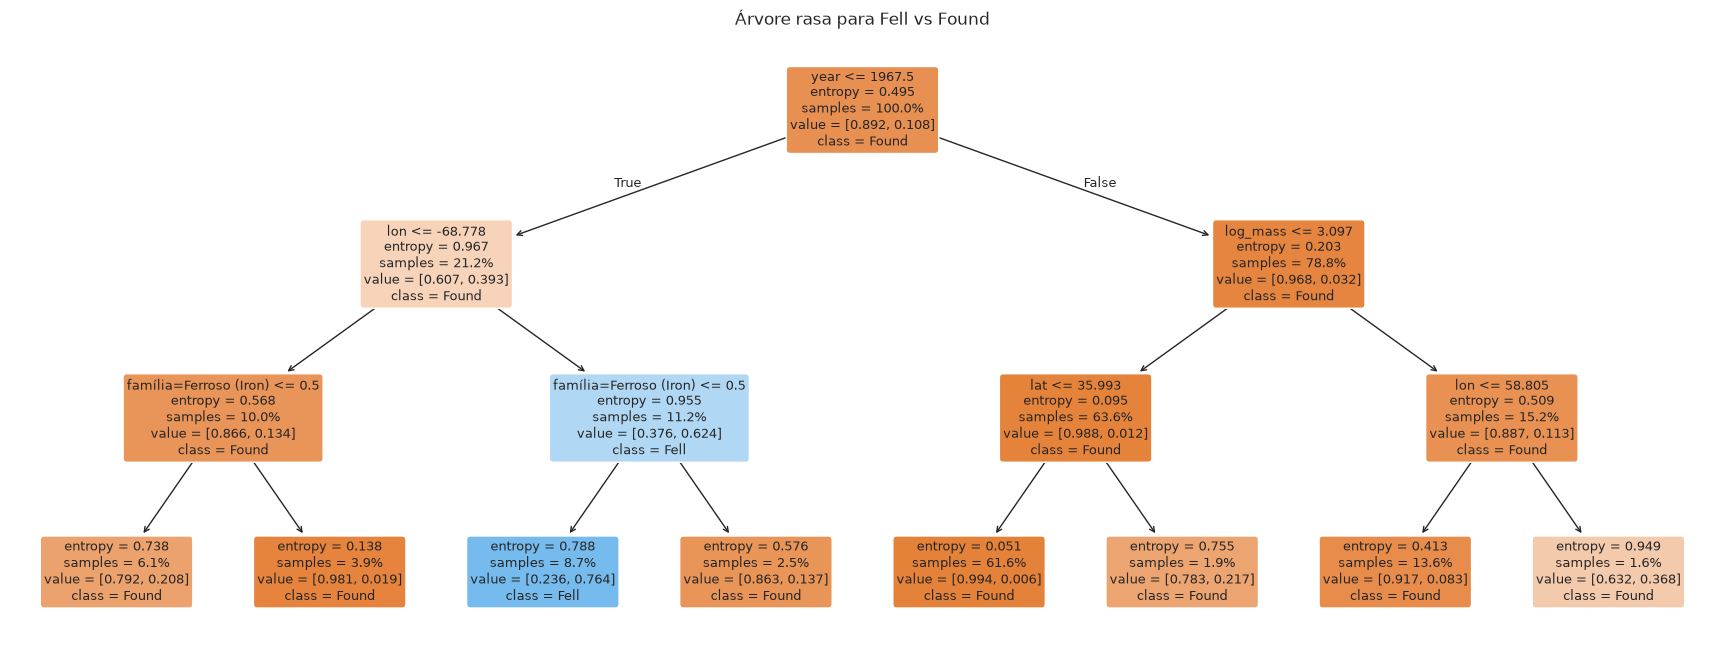

In [ ]:
# árvore rasa e legível; sem padronização, os limiares ficam em unidades reais (ano, log10 g, graus)
tree_m = make_pipeline(ColumnTransformer([("num", "passthrough", NUM),
                                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
                       DecisionTreeClassifier(max_depth=3, criterion="entropy", min_samples_leaf=30,
                                              random_state=RANDOM_STATE)).fit(Xm_tr, ym_tr)
fn = [n.replace("num__", "").replace("cat__class_group_", "família=") for n in tree_m[0].get_feature_names_out()]
print("AUC_ROC (teste):", round(roc_auc_score(ym_te, tree_m.predict_proba(Xm_te)[:, 1]), 3))
print(export_text(tree_m[-1], feature_names=fn, decimals=2))
plt.figure(figsize=(22, 8))
plot_tree(tree_m[-1], feature_names=fn, class_names=["Found", "Fell"], filled=True,
          rounded=True, proportion=True, fontsize=9)
plt.title("Árvore rasa para Fell vs Found")
plt.show()

## B5. Árvore sobre atributos categóricos (Aula 5)

A proposta sugere analisar atributos categóricos com árvores. Discretizamos os contínuos em categorias interpretáveis:
- **época:** antes de 1900, 1900–1968, 1969–1999, 2000 em diante (1969 marca o início da coleta na Antártida);
- **faixa de massa:** < 100 g, 100 g–1 kg, 1–10 kg, > 10 kg;
- **hemisfério:** Norte ou Sul;
- **família mineralógica.**

Primeiro calculamos o **ganho de informação** (entropia de Shannon) de cada atributo isolado em relação a `fall`, que é exatamente o critério que a árvore usa para escolher a primeira divisão.

In [ ]:
cat_df = mdf.copy()
cat_df["epoca"] = pd.cut(cat_df["year"], [0, 1899, 1968, 1999, 3000],
                         labels=["<1900", "1900-1968", "1969-1999", "2000+"])
cat_df["faixa_massa"] = pd.cut(cat_df["mass_g"], [0, 100, 1_000, 10_000, np.inf],
                               labels=["<100 g", "100 g-1 kg", "1-10 kg", ">10 kg"])
cat_df["hemisferio"] = np.where(cat_df["lat"] >= 0, "Norte", "Sul")
CATS = ["epoca", "faixa_massa", "hemisferio", "class_group"]

ig = pd.Series({c: information_gain(cat_df, c, "fall") for c in CATS}).sort_values(ascending=False)
print(f"Entropia de fall (fora da Antártida): {entropy(cat_df['fall'].value_counts(normalize=True)):.3f} bits")
display(ig.to_frame("ganho de informação (bits)"))

for c in ["epoca", "faixa_massa"]:
    display(pd.crosstab(cat_df[c], cat_df["fall"], normalize="index").round(3)
              .assign(n=cat_df[c].value_counts()))

Entropia de fall (fora da Antártida): 0.495 bits


,ganho de informação (bits)
epoca,0.141
faixa_massa,0.048
class_group,0.011
hemisferio,0.000


fall,Fell,Found,n
epoca,,,
<1900,0.542,0.458,705
1900-1968,0.307,0.693,1435
1969-1999,0.051,0.949,3342
2000+,0.016,0.984,4331


fall,Fell,Found,n
faixa_massa,,,
<100 g,0.029,0.971,2715
100 g-1 kg,0.068,0.932,3835
1-10 kg,0.215,0.785,2088
>10 kg,0.233,0.767,1175


Árvore categórica (CV): AUC_ROC = 0.905 | AUC_PR = 0.599
|--- epoca_<1900 <= 0.50
|   |--- epoca_1900-1968 <= 0.50
|   |   |--- faixa_massa_>10 kg <= 0.50
|   |   |   |--- faixa_massa_1-10 kg <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- faixa_massa_1-10 kg >  0.50
|   |   |   |   |--- class: 0
|   |   |--- faixa_massa_>10 kg >  0.50
|   |   |   |--- class_group_Ferroso (Iron) <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- class_group_Ferroso (Iron) >  0.50
|   |   |   |   |--- class: 0
|   |--- epoca_1900-1968 >  0.50
|   |   |--- class_group_Ferroso (Iron) <= 0.50
|   |   |   |--- class_group_Acondrito <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- class_group_Acondrito >  0.50
|   |   |   |   |--- class: 1
|   |   |--- class_group_Ferroso (Iron) >  0.50
|   |   |   |--- hemisferio_Sul <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- hemisferio_Sul >  0.50
|   |   |   |   |--- class: 0
|--- epoca_<1900 >  0.50
|   |--- class_group_Ferroso (Iron) <= 0.50

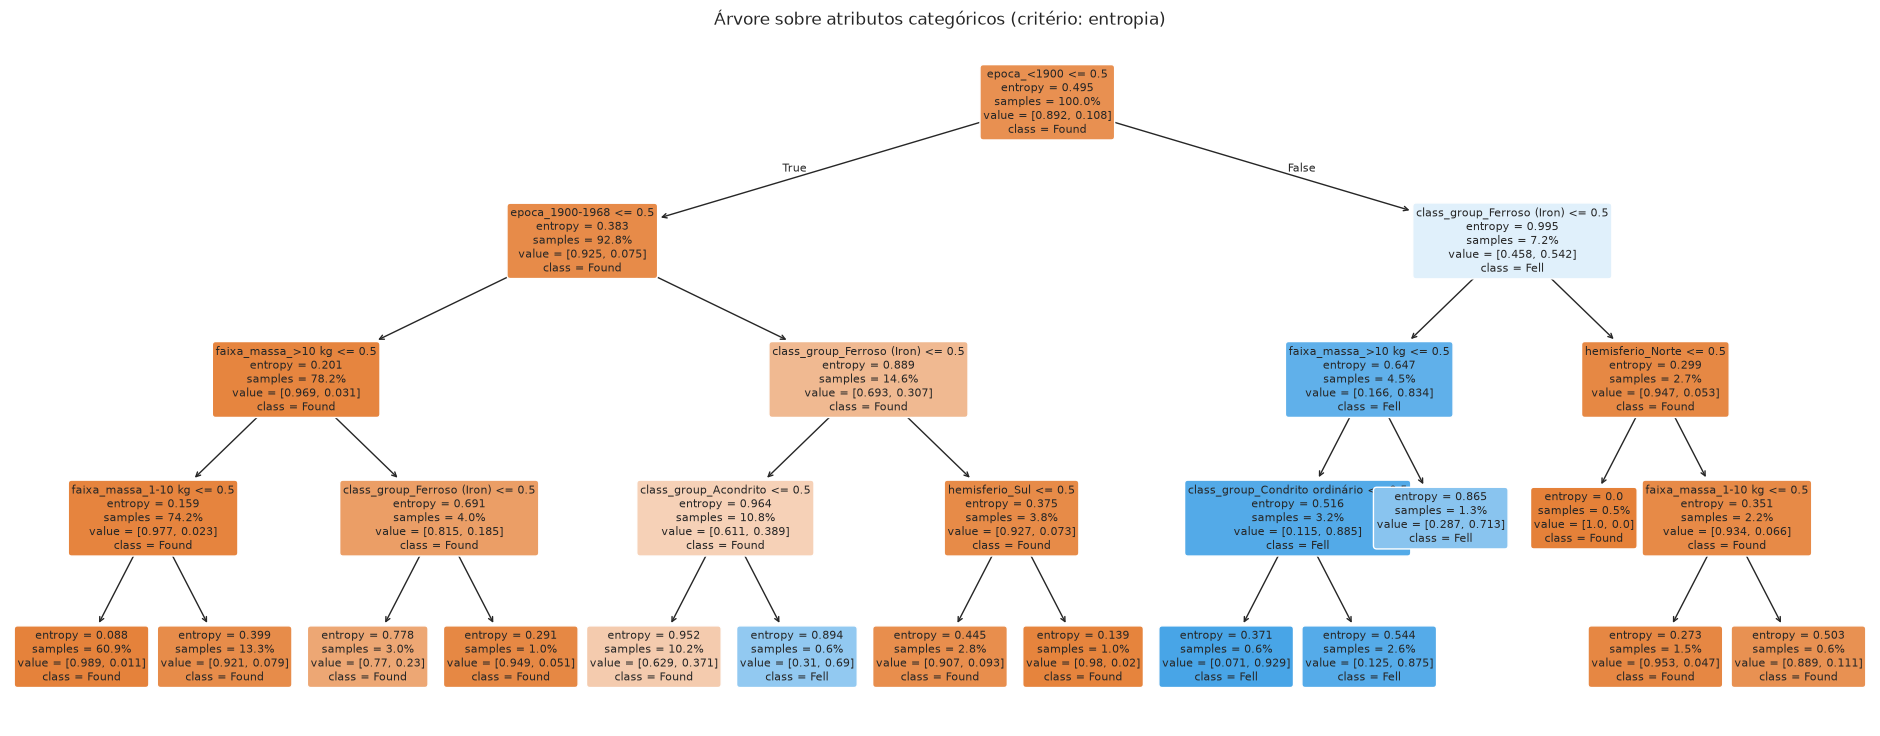

In [ ]:
Xc = cat_df[CATS].astype(str); yc = cat_df["fell"].values
cat_tree = make_pipeline(OneHotEncoder(handle_unknown="ignore"),
                         DecisionTreeClassifier(criterion="entropy", max_depth=4, min_samples_leaf=50,
                                                random_state=RANDOM_STATE))
cv_cat = cross_validate(cat_tree, Xc, yc, cv=CV, scoring={"AUC_ROC": "roc_auc", "AUC_PR": "average_precision"})
print(f"Árvore categórica (CV): AUC_ROC = {cv_cat['test_AUC_ROC'].mean():.3f} | "
      f"AUC_PR = {cv_cat['test_AUC_PR'].mean():.3f}")

cat_tree.fit(Xc, yc)
fn_c = cat_tree[0].get_feature_names_out(CATS)
print(export_text(cat_tree[-1], feature_names=list(fn_c)))
plt.figure(figsize=(24, 9))
plot_tree(cat_tree[-1], feature_names=fn_c, class_names=["Found", "Fell"], filled=True,
          rounded=True, proportion=True, fontsize=8)
plt.title("Árvore sobre atributos categóricos (critério: entropia)")
plt.show()

**Como ler os nós:** cada divisão binária tem a forma `atributo_categoria <= 0.5`. O ramo da esquerda é **não pertence** à categoria; o da direita, **pertence**. Leia as folhas como regras do tipo "se época ≥ 1969 e massa < 100 g, então Found com X% de pureza".

### Anotações da Parte B para o relatório (preenchidas em `CONCLUSOES.md`)
- **H2 (massa na Antártida)**
- **H3 sem Antártida (mediana, Mann-Whitney, coeficiente de `fell` na regressão)**
- **H4 sem Antártida (Iron entre os Found)**
- **H1 temporal (proporção de Fell por década)**
- **Comparação de conjuntos de atributos (meteorito × contexto)**
- **Regras da árvore categórica e ganho de informação**

---
# Justificativa de modelos não usados
- **Pulsares, árvores e ensembles:** usados só como referência, porque não há atributos categóricos.
- **Pulsares, SVM polinomial e sigmoide:** o kernel RBF cobre o caso não linear; o polinomial é instável com caudas longas e muito mais lento.
- **Pulsares, SVM de margem rígida:** não tem solução, porque os dados não são linearmente separáveis (seção A3).
- **Pulsares, Softmax e SVM One-vs-One:** o problema é binário.
- **Meteoritos, SVM, KNN e MLP:** os atributos são mistos (one-hot + coordenadas geográficas sem métrica euclidiana natural). As árvores lidam bem com isso e produzem **regras legíveis**, que são o objetivo do passo 6.
- **Meteoritos, PCA:** apenas 4 atributos contínuos, de naturezas diferentes (massa, tempo, espaço). Uma combinação linear deles não tem interpretação física.